In [64]:
import torch
import random

In [ ]:
n_way = 5
k_shot = 5
q_query = 5

In [66]:
background_root='../omniglot/python/images_background'
evaluation_root='../omniglot/python/images_evaluation'
model_root=f'../models/SiameseNet_{n_way}_{k_shot}/'

In [67]:
meta_json: dict = {}

# 转储模型元数据 半结构化数据
meta_json = {
    "name": "SiameseNet",
    "architecture": "SiameseNet",
    "encoder": "CNN-4",
    "dataset": "Omniglot",
    "version": [2, 0, 0],
    "embedding_dim": 64,
}

In [68]:
from pathlib import Path

Path(model_root).mkdir(parents=True, exist_ok=True)

In [69]:
from functools import partial
import sys
from tqdm import tqdm as origin_tqdm

tqdm = partial(origin_tqdm, file=sys.stdout, ncols=100)

In [70]:
from pathlib import Path

background_path = Path(background_root)
alphabet_paths = [p for p in background_path.iterdir() if p.is_dir()]
selected_alphabet_paths = random.sample(alphabet_paths, round(len(alphabet_paths) * 0.2))

train_path = background_path / 'train'
val_path = background_path / 'val'

train_root = train_path.as_posix()
val_root = val_path.as_posix()

if not val_path.exists():
    train_path.mkdir(exist_ok=True)
    val_path.mkdir(exist_ok=True)

    for alphabet_path in selected_alphabet_paths:
        alphabet_path.move_into(val_path)

    for alphabet_path in background_path.iterdir():
        if alphabet_path.is_dir() and alphabet_path not in [train_path, val_path]:
            alphabet_path.move_into(train_path)

In [71]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

device

device(type='cuda')

In [72]:
from pathlib import Path
from typing import Iterator, override

from torch import Tensor
import torch.nn as nn
from torch.utils.data import IterableDataset
from torchvision.io import decode_image


class EpisodeDataset(IterableDataset):
    def __init__(self, root: str, n_way: int, k_shot: int, q_query: int, transform: nn.Module | None = None) -> None:
        super().__init__()

        self.root = root
        self.n_way = n_way
        self.k_shot = k_shot
        self.q_query = q_query
        self.transform = transform

        self.alphabet_to_characters_to_images: dict[str, dict[str, list[Tensor]]] = {}

        self._load()

    def _load(self) -> None:
        root_path = Path(self.root)

        for alphabet_path in root_path.iterdir():
            if not alphabet_path.is_dir():
                continue

            for character_path in alphabet_path.iterdir():
                if not character_path.is_dir():
                    continue

                for image_path in character_path.iterdir():
                    if not image_path.is_file():
                        continue

                    image = self._load_image(image_path.as_posix())

                    self.alphabet_to_characters_to_images.setdefault(alphabet_path.as_posix(), {}).setdefault(character_path.as_posix(), []).append(image)

        if len(self.alphabet_to_characters_to_images) == 0:
            raise ValueError(f'Must have at least one character with images in {self.root}')

        # print(self.alphabet_to_characters_to_images[r'omniglot/python/images_background/Alphabet_of_the_Magi/character01'])

    def _load_image(self, path_str: str) -> Tensor:
        image = decode_image(path_str)

        if self.transform:
            image = self.transform(image)

        image: Tensor = image.float() / 255

        return image

    @override
    def __iter__(self) -> Iterator[tuple[Tensor, Tensor, Tensor, Tensor]]:
        while True:
            # 选中的字母表下的所有字符
            # {'omniglot/python/images_background/Alphabet_of_the_Magi/character01': [T...], ...}
            selected_characters_to_images = random.choice(tuple(self.alphabet_to_characters_to_images.values()))

            # 选中的字母表下的n_way个字符
            # [Tensor, Tensor, ...]
            selected_images = random.sample(tuple(selected_characters_to_images.values()), self.n_way) 

            # print(selected_characters_to_images, selected_images.__len__(), selected_images[0].__len__())

            support_list: list[Tensor] = []
            support_labels_list: list[int] = []
            query_list: list[Tensor] = []
            query_labels_list: list[int] = []

            for i, images in enumerate(selected_images):
                images: list[Tensor] = random.sample(images, self.k_shot + self.q_query)

                support_list += images[: self.k_shot]
                support_labels_list += [i] * self.k_shot
                query_list += images[self.k_shot :]
                query_labels_list += [i] * self.q_query

            support = torch.stack(support_list)
            support_labels = torch.tensor(support_labels_list)
            query = torch.stack(query_list)
            query_labels = torch.tensor(query_labels_list)

            yield support, support_labels, query, query_labels

In [73]:
from typing import Literal


class PairDataset(EpisodeDataset):
    def __init__(self, root: str, n_way: int, k_shot: int, q_query: int, transform: nn.Module | None = None) -> None:
        super().__init__(root=root,n_way=n_way,k_shot=k_shot,q_query=q_query,transform=transform)

    @override
    def __iter__(self) -> Iterator[tuple[Tensor, Tensor, Literal[0, 1]]]:
        while True:
            # 选中的字母表下的所有字符
            # {'omniglot/python/images_background/Alphabet_of_the_Magi/character01': [T...], ...}
            selected_characters_to_images = random.choice(tuple(self.alphabet_to_characters_to_images.values()))

            # 选中的字母表下的 2 个字符
            # [Tensor, Tensor]
            class_a_images, class_b_images = random.sample(tuple(selected_characters_to_images.values()), 2) 

            # print(selected_characters_to_images, selected_images.__len__(), selected_images[0].__len__())

            anchor, positive = random.sample(class_a_images, 2)
            negative = random.choice(class_b_images)

            yield anchor, positive, 1
            yield anchor, negative, 0

In [74]:
class Encoder(nn.Module):
    def __init__(self, in_channels=1, feature_channels=64, embed_dim=64) -> None:
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels, feature_channels, 3, padding=1),
            nn.BatchNorm2d(feature_channels),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(feature_channels, feature_channels, 3, padding=1),
            nn.BatchNorm2d(feature_channels),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(feature_channels, feature_channels, 3, padding=1),
            nn.BatchNorm2d(feature_channels),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(feature_channels, embed_dim, 3, padding=1),
            nn.BatchNorm2d(embed_dim),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1)  # (batch, embed_dim, 1, 1)
        )

    def forward(self, x: Tensor):
        x = self.encoder(x)
        return x.view(x.size(0), -1)  # flatten to (batch, embed_dim)

In [75]:
class SiameseNet(nn.Module):
    def __init__(self) -> None:
        super().__init__()

    def forward(self, embed_support: Tensor, support_labels: Tensor, embed_query: Tensor) -> Tensor:
        '''
        support: (n_way*k_shot, 1, H, W)
        support_labels: (n_way*k_shot,)
        query: (n_way*q_query, 1, H, W)

        return:
            logits: (n_way*q_query, n_way)
        '''
        current_n_way = torch.max(support_labels) + 1
        num_query = embed_query.size(0)

        torch._check(current_n_way.item() > 0)
        
        # 1. 计算 Query 与 Support 中每一张图的负欧氏距离
        # 使用广播机制计算: (Q, 1, D) 与 (1, S, D) 的距离 -> (Q, S)
        # dist_matrix 形状: (Q, S)
        # 计算各自平方和
        query_norm_sq = (embed_query**2).sum(dim=1, keepdim=True)  # [num_query, 1]
        proto_norm_sq = (embed_support**2).sum(dim=1).unsqueeze(0)  # [1, num_class]

        # 计算负的两倍内积
        cross_term = 2 * embed_query @ embed_support.t()  # [num_query, num_class]

        # 合并
        # clamp 防止计算误差
        dist_matrix = torch.sqrt(torch.clamp(query_norm_sq + proto_norm_sq - cross_term, min=1e-7))  # [num_query, num_class]

        
        # 转化为负距离得分 (Logits)
        # scores 形状: (Q, S)
        scores = -dist_matrix

        # 2. 核心逻辑：按类别聚合得分
        # 需要将 scores (Q, S) 按照 support_labels 归类到 (Q, n_way)
        # 初始化输出张量
        logits = embed_query.new_zeros(num_query, current_n_way)
        
        # 将 support_labels 扩展，以便在 dim=1 (S 维度) 上进行 scatter_reduce
        # index 形状: (Q, S)
        index = support_labels.unsqueeze(0).expand(num_query, -1)
        
        # 使用 scatter_reduce 的 'mean' 模式
        # 这会自动处理每个类别样本数不等的情况 (不依赖固定 k_shot)
        logits = logits.scatter_reduce(
            dim=1, 
            index=index, 
            src=scores, 
            reduce='mean', 
            include_self=False
        )

        return logits

In [76]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ContrastiveLoss(nn.Module):
    def __init__(self, margin=1.0):
        super().__init__()
        self.margin = margin

    def forward(self, emb1, emb2, label):
        # normalize（防 collapse）
        emb1 = F.normalize(emb1, dim=1)
        emb2 = F.normalize(emb2, dim=1)

        dist = F.pairwise_distance(emb1, emb2)  # [B]

        loss_pos = label * dist.pow(2)
        loss_neg = (1 - label) * torch.clamp(self.margin - dist, min=0).pow(2)

        loss = loss_pos + loss_neg
        return loss.mean()

In [77]:
train_set = PairDataset(root=train_root, n_way=n_way, k_shot=k_shot, q_query=q_query)
val_set = EpisodeDataset(root=val_root, n_way=n_way, k_shot=k_shot, q_query=q_query)
test_set = EpisodeDataset(root=evaluation_root, n_way=n_way, k_shot=k_shot, q_query=q_query)

In [78]:
from torch.utils.data import DataLoader

train_loader: DataLoader[Tensor] = DataLoader(train_set, batch_size=128)
val_loader: DataLoader[Tensor] = DataLoader(val_set, batch_size=None)
test_loader: DataLoader[Tensor] = DataLoader(test_set, batch_size=None)

In [79]:
encoder = Encoder(in_channels=1, feature_channels=64, embed_dim=64).to(device)
siamese_net = SiameseNet().to(device)

optimizer = torch.optim.AdamW(encoder.parameters(), lr=0.001, weight_decay = 1e-4)
loss_fn = ContrastiveLoss(margin=0.2)

In [80]:
import torch.nn.functional as F


epochs = 30
batches = 128
val_batches = 128

train_logs = []

for epoch in range(epochs):
    encoder.train()
    total_loss = 0

    for i, (x1, x2, label) in tqdm(enumerate(train_loader), total=batches, desc=f'Epoch {epoch:3d}'):
        if i >= batches:
            break

        x1: Tensor = x1.to(device)
        x2: Tensor = x2.to(device)
        label: Tensor = Tensor(label).to(device)

        optimizer.zero_grad()

        embed_x1: Tensor = encoder(x1)
        embed_x2: Tensor = encoder(x2)

        loss: Tensor = loss_fn(embed_x1, embed_x2, label)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    encoder.eval()

    val_total_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for i, (support, support_labels, query, query_labels) in tqdm(enumerate(val_loader), total=val_batches, desc='      Val', leave=False):
            if i >= val_batches:
                break

            support: Tensor = support.to(device)
            query: Tensor = query.to(device)
            support_labels: Tensor = support_labels.to(device)
            query_labels: Tensor = query_labels.to(device)

            embed_query=encoder(query)
            embed_support=encoder(support)

            # emb_support: [N*K, D]
            # emb_query: [Q, D]

            logits = siamese_net(embed_support, support_labels, embed_query)
            confidences = F.softmax(logits, dim=1) # (Q, n_way)
            pred_labels = confidences.argmax(dim=1)
            val_correct += (pred_labels == query_labels).sum().item()

            # print(support_labels[:10])
            # print(query_labels[:10])    
            # print(idx[:10])
            
            # print(embed_query[0][:10])
            # print(embed_query[1][:10])

            val_total += query_labels.size(0)

    val_accuracy = val_correct / val_total

    lrs = [param_group['lr'] for param_group in optimizer.param_groups]

    print(f'           Train Loss: {total_loss/batches} | Val Accuracy: {val_accuracy} | LR: {lrs}')

    train_logs.append({
        "epoch": epoch,
        "train_loss": total_loss/batches,
        "val_loss": None,
        "val_accuracy": val_accuracy
    })

    torch.save(encoder.state_dict(), model_root + 'last_encoder.pth')

Epoch   0: 100%|██████████████████████████████████████████████████| 128/128 [00:24<00:00,  5.21it/s]
           Train Loss: 0.006149501499749022 | Val Accuracy: 0.7746875 | LR: [0.001]                 
Epoch   1: 100%|██████████████████████████████████████████████████| 128/128 [00:24<00:00,  5.25it/s]
           Train Loss: 0.004796151441041729 | Val Accuracy: 0.8359375 | LR: [0.001]                 
Epoch   2: 100%|██████████████████████████████████████████████████| 128/128 [00:24<00:00,  5.27it/s]
           Train Loss: 0.004300594086089404 | Val Accuracy: 0.8559375 | LR: [0.001]                 
Epoch   3: 100%|██████████████████████████████████████████████████| 128/128 [00:24<00:00,  5.28it/s]
           Train Loss: 0.004047999525937485 | Val Accuracy: 0.9021875 | LR: [0.001]                 
Epoch   4: 100%|██████████████████████████████████████████████████| 128/128 [00:24<00:00,  5.27it/s]
           Train Loss: 0.003976670928750536 | Val Accuracy: 0.8878125 | LR: [0.001]        

In [81]:
from datetime import datetime


meta_json['train'] = {
            "timestamp": datetime.now().isoformat(),
            "framework": "PyTorch",

            "n_way": n_way,
            "k_shot": k_shot,
            "q_query": q_query,
            "train_batches": batches,
            "val_batches": val_batches,
    
            "logs": train_logs
}

In [82]:
test_batches = 1024

encoder.eval()

test_correct = 0
test_total = 0

with torch.no_grad():
    for i, (support, support_labels, query, query_labels) in tqdm(enumerate(test_loader), total=test_batches, desc='Test'):
        if i >= test_batches:
            break

        support: Tensor = support.to(device)
        query: Tensor = query.to(device)
        support_labels: Tensor = support_labels.to(device)
        query_labels: Tensor = query_labels.to(device)

        embed_query=encoder(query)
        embed_support=encoder(support)

        
        logits = siamese_net(embed_support, support_labels, embed_query)
        confidences = F.softmax(logits, dim=1) # (Q, n_way)
        pred_labels = confidences.argmax(dim=1)
        test_correct += (pred_labels == query_labels).sum().item()

        test_total += query_labels.size(0)

    test_accuracy = test_correct / test_total


    print(f'Test Accuracy: {test_accuracy}')

    meta_json['metrics'] = {
            "test_loss": None,
            "test_accuracy": test_accuracy,
            "n_way": n_way,
            "k_shot": k_shot,
            "q_query": q_query,
            "test_batches": test_batches
        }

Test: 100%|█████████████████████████████████████████████████████| 1024/1024 [00:17<00:00, 58.55it/s]
Test Accuracy: 0.89453125


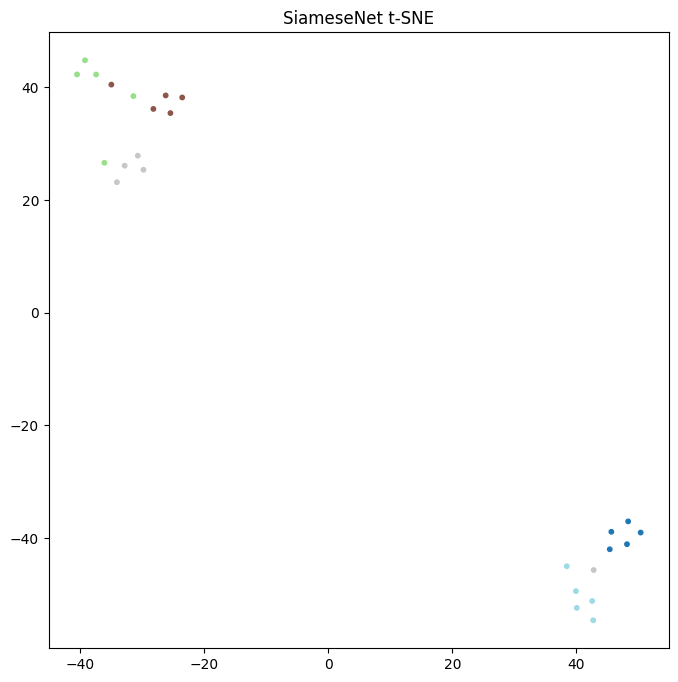

In [83]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

embeddings = []
labels = []

encoder.eval()

with torch.no_grad():
    for i, (support, support_labels, query, query_labels) in enumerate(test_loader):
        if i >= 1:
            break

        query = query.to(device)

        embed = encoder(query)

        embeddings.append(embed.cpu())
        labels.append(query_labels)

embeddings = torch.cat(embeddings)
labels = torch.cat(labels)

tsne = TSNE(n_components=2, perplexity=5)
embeddings_2d = tsne.fit_transform(embeddings.numpy())

plt.figure(figsize=(8,8))
plt.scatter(embeddings_2d[:,0], embeddings_2d[:,1], c=labels, cmap="tab20", s=10)
plt.title("SiameseNet t-SNE")
plt.savefig(model_root + "t-sne.png")
plt.show()

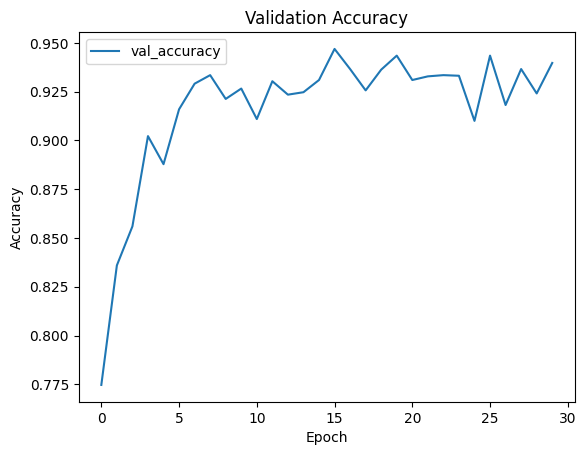

In [84]:
import matplotlib.pyplot as plt

epochs = [log["epoch"] for log in train_logs]
# train_loss = [log["train_loss"] for log in train_logs]
# val_loss = [log["val_loss"] for log in train_logs]
val_acc = [log["val_accuracy"] for log in train_logs]

# plt.figure()
# plt.plot(epochs, train_loss, label="train_loss")
# plt.plot(epochs, val_loss, label="val_loss")
# plt.legend()
# plt.title("Loss Curve")
# plt.xlabel("Epoch")
# plt.ylabel("Loss")
# plt.savefig(model_root + "loss_curve.png")

plt.figure()
plt.plot(epochs, val_acc, label="val_accuracy")
plt.legend()
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.savefig(model_root + "accuracy_curve.png")

plt.show()

## 导出模型为独立 ATen 图文件

In [85]:
# 分别导出特征提取器 (Encoder) 和 孪生网络逻辑 (SiameseNet)

import torch
from torch.export import export, save, Dim

# 从已有 test_loader 获取真实数据
for support, support_labels, query, query_labels in test_loader:
    support = support.cpu()
    support_labels = support_labels.cpu()
    query = query.cpu()
    break

# 为 Encoder 准备示例输入
example_img = support[0:4]

# 确保在 eval 模式并且不计算梯度
encoder.cpu().eval()
siamese_net.cpu().eval()

with torch.no_grad():
    # 使用训练好的 encoder 获取真实的 embedding
    embed_support = encoder(support)
    embed_query = encoder(query)

# 定义动态维度 (让模型适应不同的 Way/Shot/Query 数量)
s = Dim.AUTO
q = Dim.AUTO

# 导出 Encoder，允许 batch_size 动态变化
exported_encoder = export(
    encoder, 
    args=(example_img,), 
    dynamic_shapes={"x": {0: Dim.AUTO}}
)
save(exported_encoder, model_root + "encoder.pt2")

# 导出 SiameseNet，传入真实的特征、真实的标签，并标记维度为动态
exported_siamese = export(
    siamese_net,
    args=(embed_support, support_labels, embed_query),
    dynamic_shapes={
        "embed_support": {0: s},
        "support_labels": {0: s},
        "embed_query": {0: q}
    }
)
save(exported_siamese, model_root + "siamesenet-classifier.pt2")

In [86]:
meta_json['files'] = {
    "models": {
        "encoder": "encoder.pt2",
        "classifier": "siamesenet-classifier.pt2"
    },
    "images": {
        "accuracy_curve": "accuracy_curve.png",
        "t_sne": "t-sne.png"
    }
}

In [87]:
import json


with open(model_root + 'meta.json', 'w') as file:
    json.dump(meta_json, file, indent=2)